# Background Removal — Method Comparison

Compares three background-removal approaches on a galvanizing video:

1. **Baseline** — per-frame brightness flattening + global temporal median
2. **Global frame-average** — background = mean of all frames
3. **Sliding-window frame-average** — background = mean of nearby frames

Edit the `videoPath` cell below, then run all cells in order.

## 0 — Imports

In [13]:
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is on the import path
projectRoot = Path(".").resolve()
if str(projectRoot) not in sys.path:
    sys.path.insert(0, str(projectRoot))

from bg_subtract import subtract_global_median
from bg_subtract_rolling import subtract_rolling_median
from bg_methods import (
    subtractBaselineMedian,
    subtractGlobalAverage,
    subtractSlidingAverage,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
plt.rcParams["image.cmap"] = "gray"

print("Imports OK")

Imports OK


## 1 — Select Input Video

Edit `videoPath` below. Paths are relative to the project root (`Ali/`).

In [14]:
# ── EDIT THIS ──────────────────────────────────────────────────────
videoPath = Path("1/1.avi")
# ──────────────────────────────────────────────────────────────────

videoPath = videoPath.resolve()

if not videoPath.exists():
    raise FileNotFoundError(f"Video not found: {videoPath}")

resultsDir = Path("Results").resolve()
resultsDir.mkdir(parents=True, exist_ok=True)

print(f"Video:   {videoPath}")
print(f"Results: {resultsDir}")

Video:   C:\Users\aranl\Desktop\Ali\1\1.avi
Results: C:\Users\aranl\Desktop\Ali\Results


## 2 — Video Metadata

In [15]:
cap = cv2.VideoCapture(str(videoPath))
if not cap.isOpened():
    raise RuntimeError(f"OpenCV cannot open: {videoPath}")

fps = cap.get(cv2.CAP_PROP_FPS)
frameCount = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frameWidth = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frameHeight = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"FPS:          {fps}")
print(f"Frame count:  {frameCount}")
print(f"Resolution:   {frameWidth} x {frameHeight}")
if fps > 0:
    print(f"Duration:     {frameCount / fps:.2f} s")

FPS:          29.97002997002997
Frame count:  1800
Resolution:   320 x 1200
Duration:     60.06 s


## 3 — Original Frame

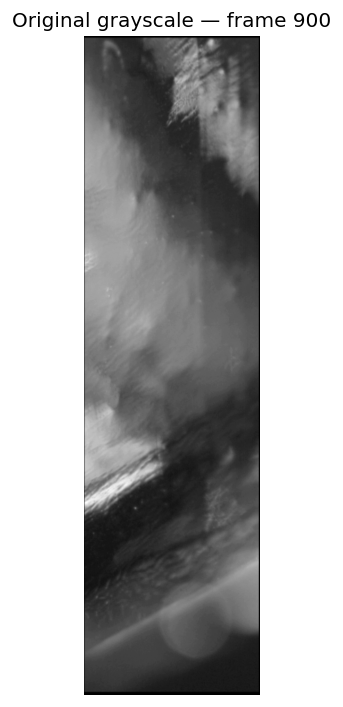

In [16]:
sampleIndex = frameCount // 2

cap = cv2.VideoCapture(str(videoPath))
cap.set(cv2.CAP_PROP_POS_FRAMES, sampleIndex)
ok, sampleBGR = cap.read()
cap.release()

if not ok:
    raise RuntimeError(f"Could not read frame {sampleIndex}")

sampleGray = cv2.cvtColor(sampleBGR, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(sampleGray, cmap="gray")
ax.set_title(f"Original grayscale — frame {sampleIndex}")
ax.axis("off")
plt.tight_layout()
plt.show()

## 4 — Baseline: Brightness Flattening + Global Temporal Median

In [17]:
baselineOutPath = resultsDir / f"{videoPath.stem}_baseline.mp4"

baselineBg, baselineOutPath = subtractBaselineMedian(
    str(videoPath),
    outPath=str(baselineOutPath),
)

print(f"\nOutput: {baselineOutPath}")

1.avi: 1799 frames, 320x1200, 29.97 fps
Baseline (flatten + global median), diff range +/-30
Saved to C:\Users\aranl\Desktop\Ali\Results\1_baseline.mp4

Output: C:\Users\aranl\Desktop\Ali\Results\1_baseline.mp4


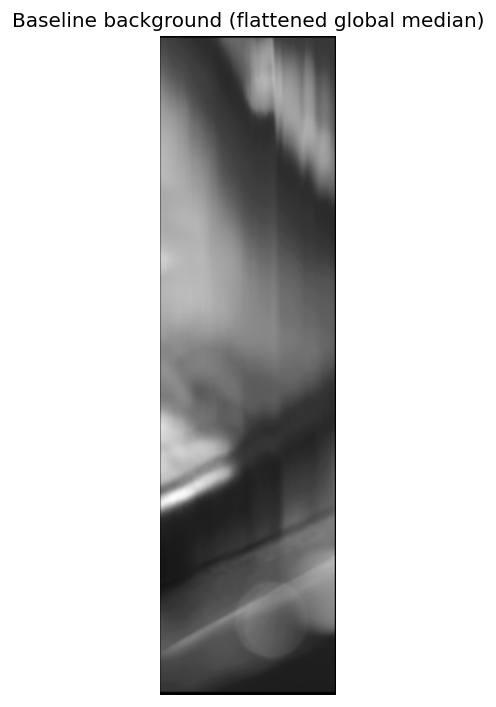

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(baselineBg, cmap="gray")
ax.set_title("Baseline background (flattened global median)")
ax.axis("off")
plt.tight_layout()
plt.show()

## 5 — Global Frame-Average Background

In [19]:
globalAvgOutPath = resultsDir / f"{videoPath.stem}_global_avg.mp4"

globalAvgBg, globalAvgOutPath = subtractGlobalAverage(
    str(videoPath),
    outPath=str(globalAvgOutPath),
)

print(f"\nOutput: {globalAvgOutPath}")

1.avi: 1799 frames, 320x1200, 29.97 fps
Global average background, diff range +/-30
Saved to C:\Users\aranl\Desktop\Ali\Results\1_global_avg.mp4

Output: C:\Users\aranl\Desktop\Ali\Results\1_global_avg.mp4


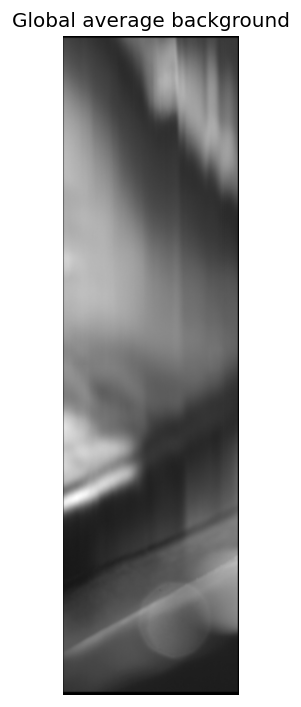

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(globalAvgBg, cmap="gray")
ax.set_title("Global average background")
ax.axis("off")
plt.tight_layout()
plt.show()

## 6 — Sliding-Window Frame-Average Background

In [21]:
slidingAvgOutPath = resultsDir / f"{videoPath.stem}_sliding_avg.mp4"

slidingAvgOutPath = subtractSlidingAverage(
    str(videoPath),
    outPath=str(slidingAvgOutPath),
)

print(f"\nOutput: {slidingAvgOutPath}")

1.avi: 1799 frames, 320x1200, 29.97 fps
Sliding average: window 187, step 30, 60 backgrounds
Diff range +/-30 -> saved to C:\Users\aranl\Desktop\Ali\Results\1_sliding_avg.mp4

Output: C:\Users\aranl\Desktop\Ali\Results\1_sliding_avg.mp4


## 7 — Read Processed Frames for Comparison

Read the same frame index from each output video.

In [22]:
def readFrameGray(videoFile, index):
    """Read a single grayscale frame from a video file."""
    cap = cv2.VideoCapture(str(videoFile))
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frameBGR = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"Could not read frame {index} from {videoFile}")
    return cv2.cvtColor(frameBGR, cv2.COLOR_BGR2GRAY)

baselineFrame = readFrameGray(baselineOutPath, sampleIndex)
globalAvgFrame = readFrameGray(globalAvgOutPath, sampleIndex)
slidingAvgFrame = readFrameGray(slidingAvgOutPath, sampleIndex)

print(f"Read frame {sampleIndex} from all three outputs.")

Read frame 900 from all three outputs.


## 8 — Side-by-Side Comparison

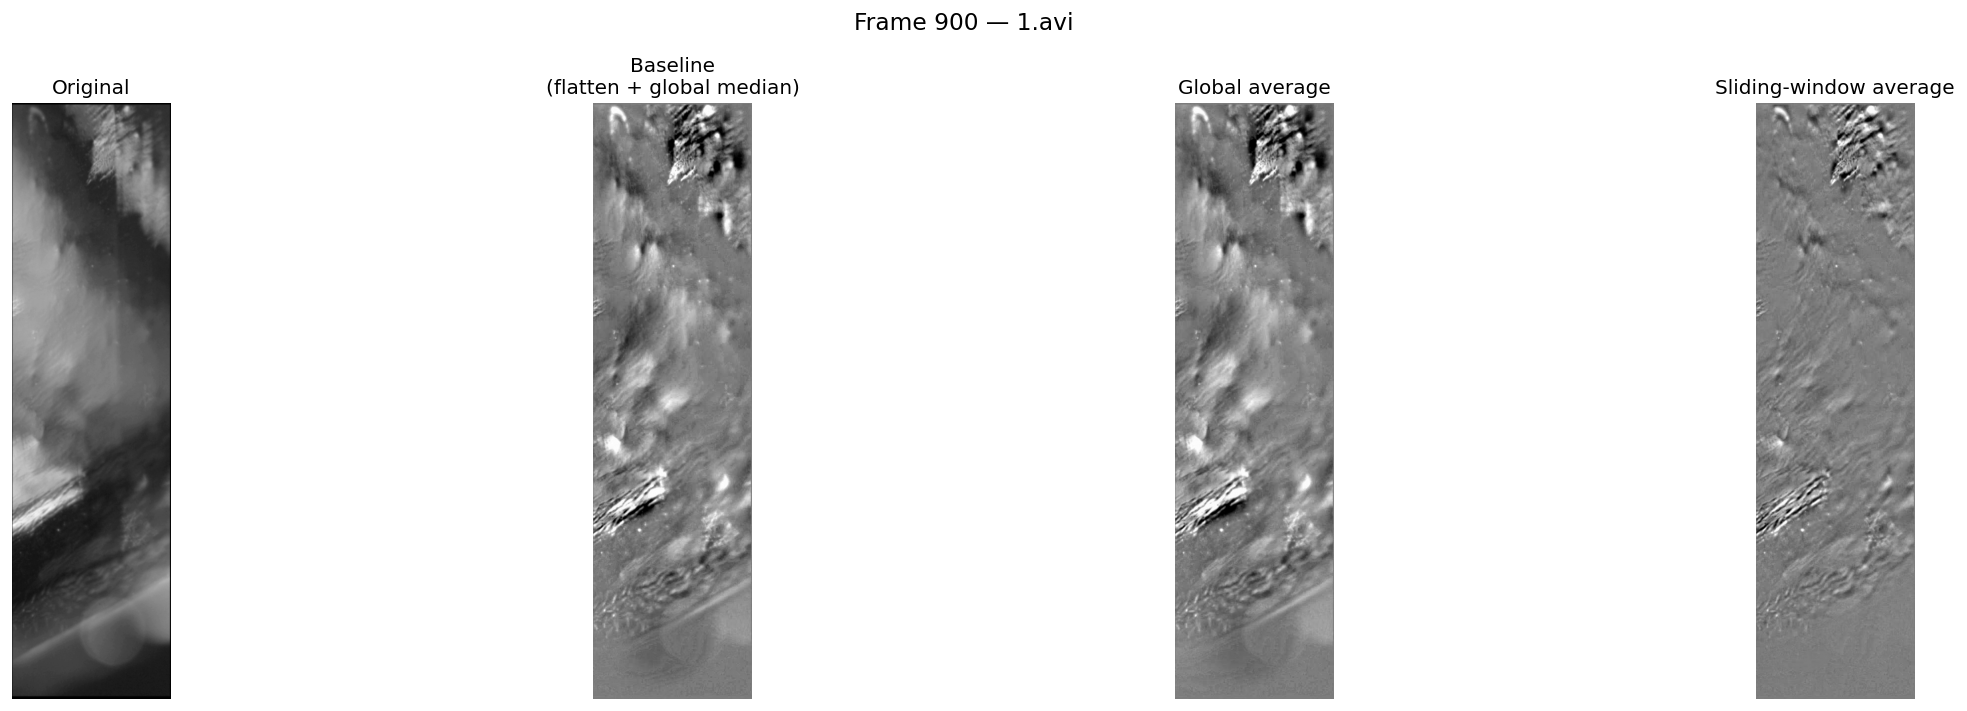

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(22, 6))

panels = [
    (sampleGray,      "Original"),
    (baselineFrame,   "Baseline\n(flatten + global median)"),
    (globalAvgFrame,  "Global average"),
    (slidingAvgFrame, "Sliding-window average"),
]

for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"Frame {sampleIndex} — {videoPath.name}", fontsize=14)
plt.tight_layout()
plt.show()

## 9 — Intensity Histograms

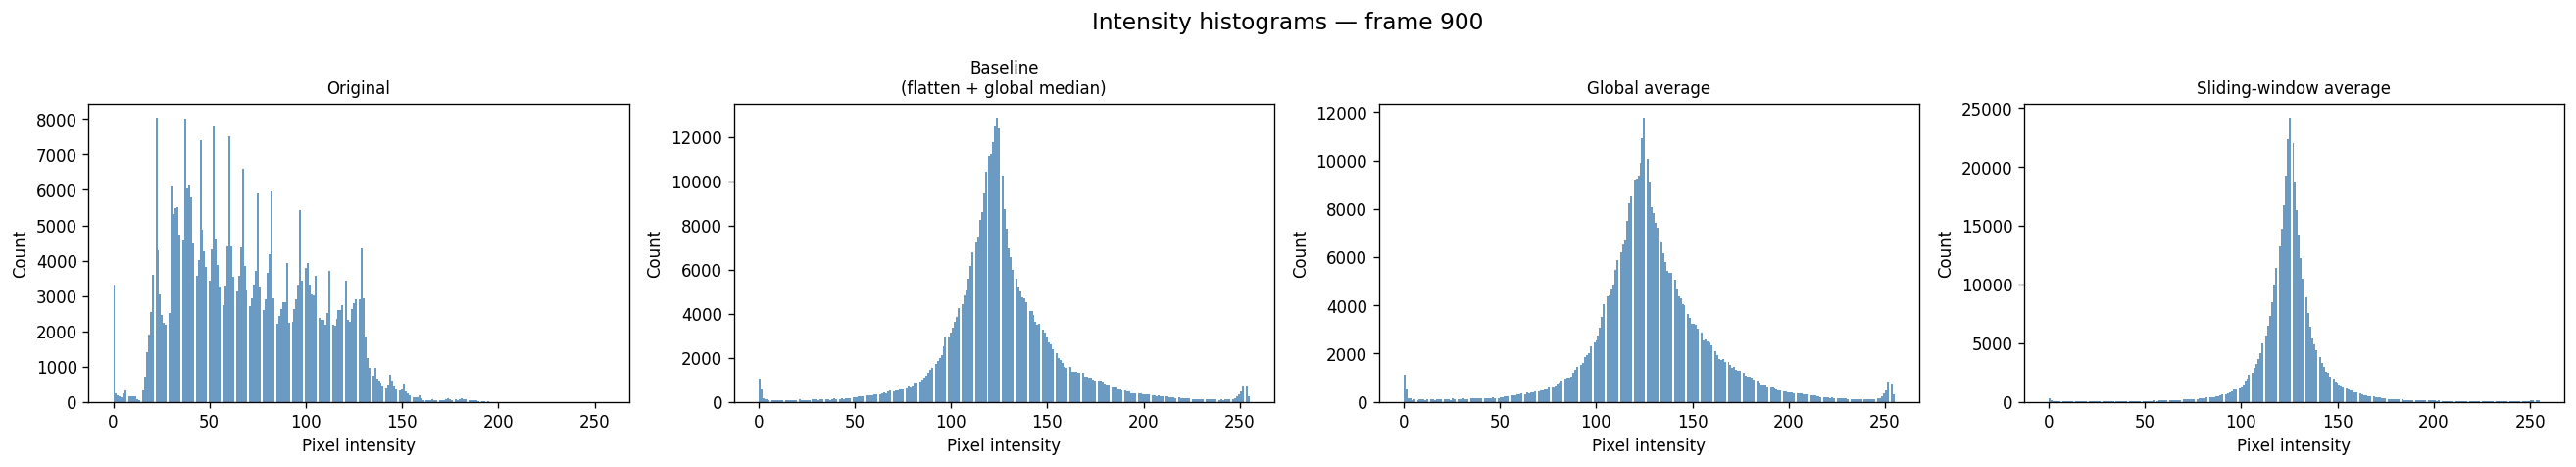

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4))

for ax, (img, label) in zip(axes, panels):
    ax.hist(img.ravel(), bins=256, range=(0, 255), color="steelblue", alpha=0.8)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Pixel intensity")
    ax.set_ylabel("Count")

fig.suptitle(f"Intensity histograms — frame {sampleIndex}", fontsize=14)
plt.tight_layout()
plt.show()

## 10 — Background Images Comparison

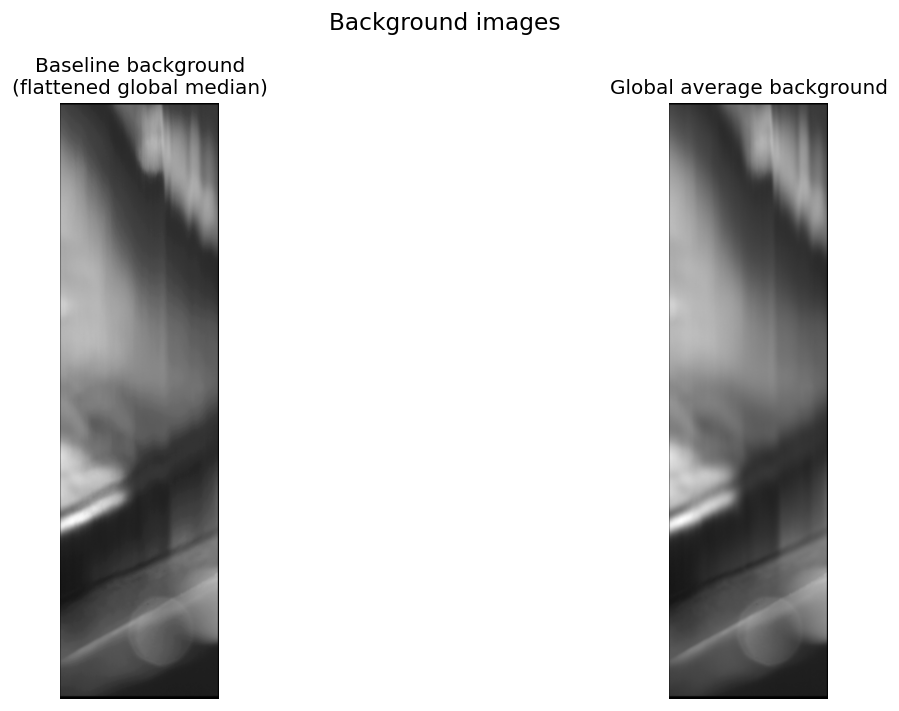

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(baselineBg, cmap="gray")
axes[0].set_title("Baseline background\n(flattened global median)")
axes[0].axis("off")

axes[1].imshow(globalAvgBg, cmap="gray")
axes[1].set_title("Global average background")
axes[1].axis("off")

fig.suptitle("Background images", fontsize=14)
plt.tight_layout()
plt.show()